<a href="https://colab.research.google.com/github/vidhijamadar0732-coder/Datheon_Data_Analytics_Power_BI_Internship-4./blob/main/Task3_Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [70]:

import pandas as pd

df = pd.read_csv('/content/telco_customer_churn.csv')

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [71]:

# Check dataset size
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display first 5 rows
df.head()


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [72]:

# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows:
0


In [73]:

# Remove duplicate records
df = df.drop_duplicates()

# Remove extra spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Convert TotalCharges into numeric values
if 'TotalCharges' in df.columns:
    df['TotalCharges'] = pd.to_numeric(
        df['TotalCharges'], errors='coerce'
    )

# Check missing values again
print(df.isnull().sum())

print("Data cleaning completed!")


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
Data cleaning completed!


In [74]:

# Count customers
total_customers = len(df)

# Count customers who left
churned_customers = (df['Churn'] == 'Yes').sum()

# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Customer Churn Rate:", round(churn_rate, 2), "%")


Total Customers: 7043
Churned Customers: 1869
Customer Churn Rate: 26.54 %


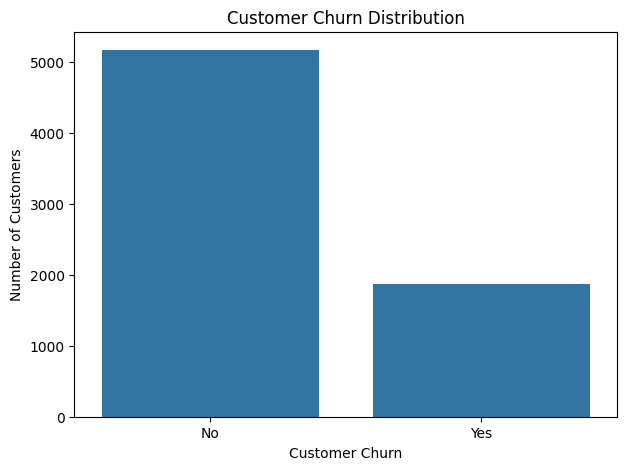

In [75]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.show()


Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


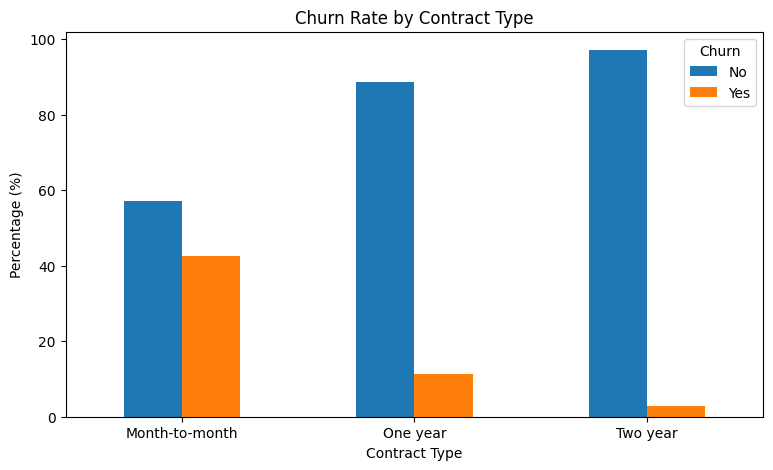

In [76]:

contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn)

contract_churn.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.show()


Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


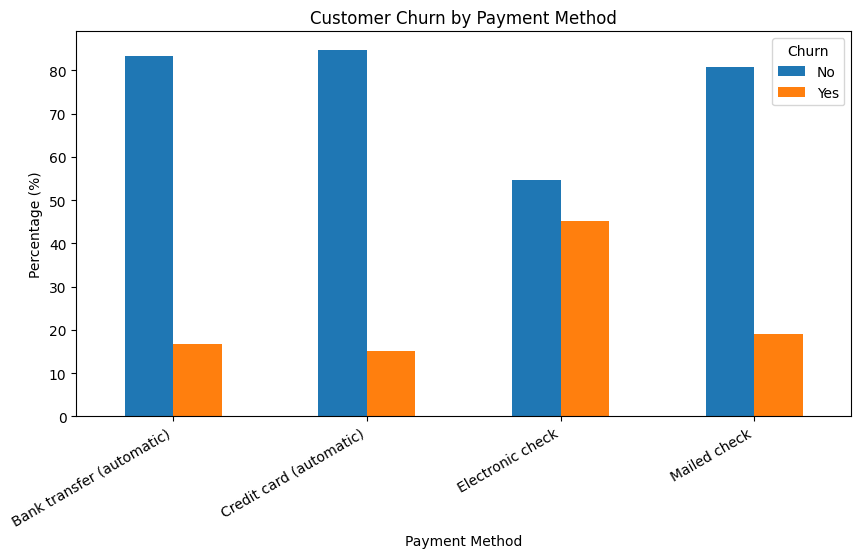

In [77]:

payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn)

payment_churn.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=30, ha='right')
plt.show()


Churn                No        Yes
Tenure_Group                      
0-12 Months   52.561757  47.438243
13-24 Months  71.289062  28.710938
25-36 Months  78.365385  21.634615
37-48 Months  80.971129  19.028871
49-60 Months  85.576923  14.423077
61-72 Months  93.390192   6.609808


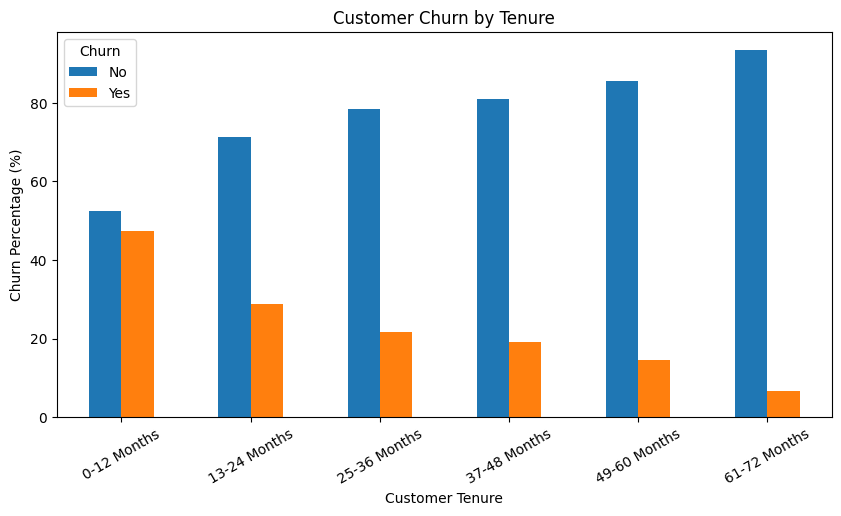

In [78]:

# Create tenure groups
df['Tenure_Group'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-36 Months',
        '37-48 Months',
        '49-60 Months',
        '61-72 Months'
    ]
)

# Calculate churn by tenure group
tenure_churn = pd.crosstab(
    df['Tenure_Group'],
    df['Churn'],
    normalize='index'
) * 100

print(tenure_churn)

tenure_churn.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Customer Churn by Tenure')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Percentage (%)')
plt.xticks(rotation=30)
plt.show()


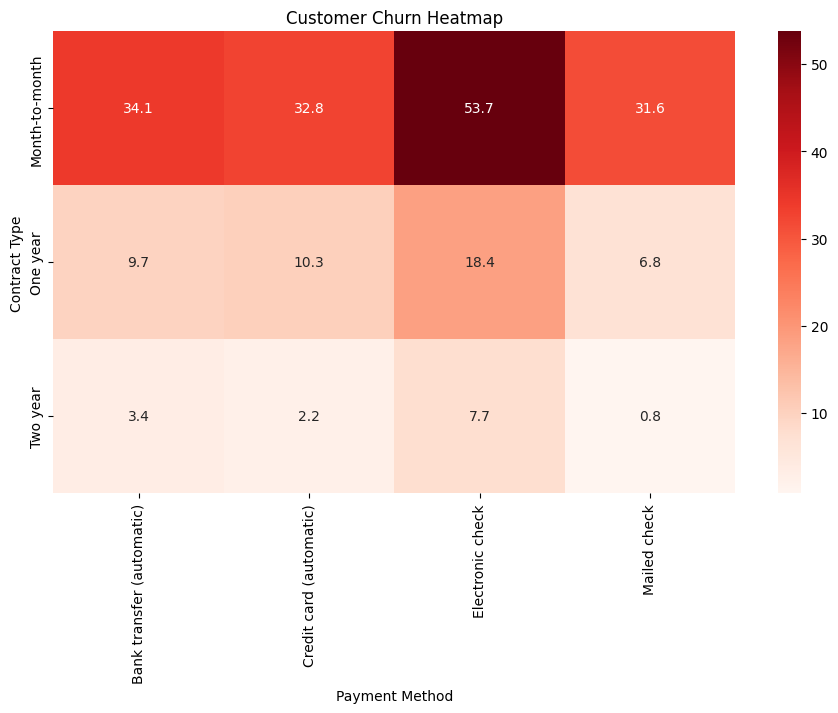

In [79]:

# Create churn heatmap
heatmap_data = pd.crosstab(
    df['Contract'],
    df['PaymentMethod'],
    values=(df['Churn'] == 'Yes').astype(int),
    aggfunc='mean'
) * 100

plt.figure(figsize=(11, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap='Reds',
    fmt='.1f'
)

plt.title('Customer Churn Heatmap')
plt.xlabel('Payment Method')
plt.ylabel('Contract Type')

plt.show()
